# 02_preprocessing

In [1]:
 
# ==========================================
# CELL 1: IMPORT LIBRARIES AND LOAD DATA
# ==========================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

# Display settings
pd.set_option("display.max_columns", None)

# Load original dataset
df = pd.read_csv("../data/telecom_customer_churn.csv")

print("Dataset loaded successfully!")
print("Original shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Original shape: (7043, 38)


,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,9,NaN,Yes,42.39,No,Yes,Cable,16.0,No,Yes,No,Yes,Yes,No,No,Yes,One Year,Yes,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,9,NaN,Yes,10.69,Yes,Yes,Cable,10.0,No,No,No,No,No,Yes,Yes,No,Month-to-Month,No,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,4,Offer E,Yes,33.65,No,Yes,Fiber Optic,30.0,No,No,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,13,Offer D,Yes,27.82,No,Yes,Fiber Optic,4.0,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,3,NaN,Yes,7.38,No,Yes,Fiber Optic,11.0,No,No,No,Yes,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [2]:

# ==========================================
# CELL 2: SELECT FEATURES AND TARGET
# ==========================================

# Define our 15 input features
features = [
    "Age",
    "Married",
    "Number of Dependents",
    "Number of Referrals",
    "Tenure in Months",
    "Internet Service",
    "Internet Type",
    "Online Security",
    "Online Backup",
    "Device Protection Plan",
    "Premium Tech Support",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Monthly Charge"
]

target = "Customer Status"

# Keep only customers with known churn outcomes
model_df = df[
    df[target].isin(["Stayed", "Churned"])
].copy()

# Replace structural missing values
internet_features = [
    "Internet Type",
    "Online Security",
    "Online Backup",
    "Device Protection Plan",
    "Premium Tech Support"
]

model_df[internet_features] = (
    model_df[internet_features]
    .fillna("No Internet Service")
)

# Convert target to binary
model_df["Churn"] = (
    model_df[target] == "Churned"
).astype(int)

# Separate features and target
X = model_df[features].copy()
y = model_df["Churn"].copy()

print("Modeling dataset shape:", model_df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

print("\nMissing values:")
display(X.isnull().sum())


Modeling dataset shape: (6589, 39)
Feature matrix shape: (6589, 15)
Target shape: (6589,)

Target distribution:


Churn
0    4720
1    1869
Name: count, dtype: int64


Missing values:


Age                       0
Married                   0
Number of Dependents      0
Number of Referrals       0
Tenure in Months          0
Internet Service          0
Internet Type             0
Online Security           0
Online Backup             0
Device Protection Plan    0
Premium Tech Support      0
Contract                  0
Paperless Billing         0
Payment Method            0
Monthly Charge            0
dtype: int64

In [3]:

# ==========================================
# CELL 3: TRAIN TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).round(3))


Training features: (5271, 15)
Testing features: (1318, 15)

Training target distribution:


Churn
0    0.716
1    0.284
Name: proportion, dtype: float64


Testing target distribution:


Churn
0    0.716
1    0.284
Name: proportion, dtype: float64

# Cell 4 — Separate numerical and categorical features

In [ ]:
 
# ==========================================
# CELL 4: IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ==========================================

# Numerical features
numerical_features = [ "Age",    "Number of Dependents",    "Number of Referrals",    "Tenure in Months",    "Monthly Charge"]

# Categorical features
categorical_features = [ "Married",    "Internet Service",    "Internet Type",    "Online Security",    "Online Backup",    "Device Protection Plan",    "Premium Tech Support",    "Contract",    "Paperless Billing",    "Payment Method" ]

# Verify feature selection
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nTotal selected features:",      len(numerical_features) + len(categorical_features))

print("\nNumerical feature names:")
print(numerical_features)

print("\nCategorical feature names:")
print(categorical_features)

# Check whether all selected features are accounted for
assert set(numerical_features + categorical_features) == set(features)
# just to know all the features arein the features selection methods or not 
# ;:
print("\nSUCCESS: All 15 features are correctly categorized.")


Numerical features: 5
Categorical features: 10

Total selected features: 15

Numerical feature names:
['Age', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months', 'Monthly Charge']

Categorical feature names:
['Married', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Contract', 'Paperless Billing', 'Payment Method']

SUCCESS: All 15 features are correctly categorized.


# Cell 5 — Create the preprocessing pipeline

In [ ]:
# ==========================================
# CELL 5: CREATE PREPROCESSING PIPELINE
# ==========================================

# ------------------------------------------
# 1. Numerical preprocessing pipeline
# WHAT: Defines a sequence of steps to clean and scale numerical data (numbers).
# WHY: Machine learning models perform better when numerical features are on the same scale and have no missing values.
# ------------------------------------------
numerical_transformer = Pipeline(
    steps=[
        # WHAT: Replaces missing values (NaN) with the median of that column.
        # WHY: Median is used instead of mean because it is less affected by extreme outliers.
        ("imputer", SimpleImputer(strategy="median")),
        
        # WHAT: Standardizes features by removing the mean and scaling to unit variance.
        # WHY: Prevents features with larger ranges (like salary) from dominating features with smaller ranges (like age).
        ("scaler", StandardScaler())
    ]
)

# ------------------------------------------
# 2. Categorical preprocessing pipeline
# WHAT: Defines a sequence of steps to handle categorical data (text/labels).
# WHY: Models only understand numbers, so text categories must be converted, and missing text must be filled.
# ------------------------------------------
categorical_transformer = Pipeline(
    steps=[
        # WHAT: Replaces missing values with the most frequent value (mode) of that column.
        # WHY: This is the safest logical guess for missing categorical data.
        ("imputer", SimpleImputer(strategy="most_frequent")),
        
        # WHAT: Converts categories into binary columns (0s and 1s).
        # WHY: Turns text labels into numbers the model can compute. 
        # 'handle_unknown="ignore"' prevents the code from crashing if it sees a brand new category during testing/prediction.
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# ------------------------------------------
# 3. Combine both transformations
# WHAT: Bundles the numerical and categorical pipelines into a single preprocessor object.
# WHY: This allows you to pass your entire dataset in one go, automatically routing numeric columns to the numeric pipeline and categorical columns to the categorical pipeline.
# ------------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Output status messages to confirm the pipeline was built successfully
print("Preprocessing pipeline created successfully!")

print("\nNumerical transformation:")
print("Missing values -> Median imputation -> Standard scaling")

print("\nCategorical transformation:")
print("Missing values -> Most frequent imputation -> One-hot encoding")

print("\nAll transformations are ready.")

Preprocessing pipeline created successfully!

Numerical transformation:
Missing values -> Median imputation -> Standard scaling

Categorical transformation:
Missing values -> Most frequent imputation -> One-hot encoding

All transformations are ready.


# Cell 6 — Create and train Logistic Regression

In [6]:
# ==========================================
# CELL 6: TRAIN LOGISTIC REGRESSION
# ==========================================

# WHAT: Import the specific machine learning algorithm we want to use.
# WHY: Logistic Regression is a standard algorithm used for classification (predicting categories, like "Yes/No" or "Spam/Not Spam").
from sklearn.linear_model import LogisticRegression

# ------------------------------------------
# Create complete machine learning pipeline
# ------------------------------------------
logistic_model = Pipeline(
    steps=[
        # STEP 1: The Cleaning Phase
        # WHAT: We plug in the 'preprocessor' (the assembly line we built in Cell 5).
        # WHY: This guarantees that any data passing through this pipeline gets cleaned, scaled, and encoded automatically before the model touches it.
        ("preprocessor", preprocessor),
        
        # STEP 2: The Learning Phase
        # WHAT: We attach the Logistic Regression model to the end of the line. 
        # WHY: 'max_iter=1000' tells the algorithm it has up to 1000 attempts to adjust its internal math to find the perfect fit. Without this, it might give up too early and throw a warning.
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

# ------------------------------------------
# Train model using training data
# ------------------------------------------
# WHAT: The `.fit()` command is where the actual "machine learning" happens.
# WHY: We are giving the pipeline the raw questions (X_train) and the correct answers (y_train). 
# Under the hood, X_train gets cleaned by the preprocessor, and then the classifier studies the cleaned data to figure out the patterns that lead to y_train.
logistic_model.fit(X_train, y_train)

# Output status messages to confirm success
print("Logistic Regression training completed!")

print("\nModel details:")
print(logistic_model) # Prints a text summary of the entire pipeline structure

# WHAT: .shape[0] counts the number of rows in the dataset.
# WHY: It is good practice to verify exactly how many examples the model learned from, and how many it will be tested on later.
print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Logistic Regression training completed!

Model details:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Number of Dependents',
                                                   'Number of Referrals',
                                                   'Tenure in Months',
                                                   'Monthly Charge']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                         

# Cell 7 — Evaluate Logistic Regression

In [ ]:
# ==========================================
# CELL 7: EVALUATE LOGISTIC REGRESSION
# ==========================================

# WHAT: Import a set of "grading tools" from scikit-learn.
# WHY: We need different ways to grade our model's exam. Being 90% accurate isn't always good (for example, if it just guesses "No" every time and misses all the actual churners).
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------
# 1. Generate predictions (Taking the test)
# ------------------------------------------
# WHAT: We hand the model the exam questions (X_test) that it has never seen before.
# WHY: The `.predict()` function forces the model to make a hard, final decision for every row: 0 (Stayed) or 1 (Churned).
y_pred_lr = logistic_model.predict(X_test)

# WHAT: Instead of a hard 0 or 1, we ask for the model's confidence percentages. 
# WHY: `.predict_proba()` returns probabilities (like "I am 85% sure this person will churn"). 
# The `[:, 1]` part grabs only the probability for class '1' (Churned), ignoring class '0' (Stayed).
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# ------------------------------------------
# 2. Calculate evaluation metrics (Grading the test)
# ------------------------------------------
# WHAT: Compares the model's guesses (y_pred_lr) against the true answers (y_test).

# Accuracy: Overall, what percentage of predictions were perfectly correct?
accuracy = accuracy_score(y_test, y_pred_lr)

# Precision: Out of everyone the model *claimed* would churn, how many actually did? (Measures false alarms).
# zero_division=0 prevents the code from crashing if the model guessed 0 people would churn.
precision = precision_score(y_test, y_pred_lr, zero_division=0)

# Recall: Out of all the people who *actually* churned, how many did the model successfully find? (Measures missed opportunities).
recall = recall_score(y_test, y_pred_lr, zero_division=0)

# F1 Score: A balanced combination (average) of Precision and Recall. Great for when you care about false alarms AND missed people equally.
f1 = f1_score(y_test, y_pred_lr, zero_division=0)

# ROC-AUC: Grades how well the model's probabilities separate the two groups. 
# An AUC of 1.0 is a perfect score; 0.5 means the model is just guessing randomly.
roc_auc = roc_auc_score(y_test, y_prob_lr)

# ------------------------------------------
# 3. Display results (Printing the Report Card)
# ------------------------------------------
print("========== LOGISTIC REGRESSION RESULTS ==========")

# The :.4f rounds the numbers to 4 decimal places (e.g., 0.8532) so they are easy to read.
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

# WHAT: Prints a nice pre-formatted table showing Precision, Recall, and F1 for BOTH groups (Stayed vs Churned).
# WHY: It gives you a complete overview without having to print each metric manually.
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)

print("\n========== CONFUSION MATRIX ==========")

# WHAT: Prints a 2x2 grid showing exactly where the model got confused.
# WHY: It shows you raw numbers: [True Negatives, False Positives] on top, and [False Negatives, True Positives] on the bottom.
print(confusion_matrix(y_test, y_pred_lr))

========== LOGISTIC REGRESSION RESULTS ==========
Accuracy : 0.8384
Precision: 0.7193
Recall   : 0.7059
F1 Score : 0.7126
ROC-AUC  : 0.9059

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Stayed       0.88      0.89      0.89       944
     Churned       0.72      0.71      0.71       374

    accuracy                           0.84      1318
   macro avg       0.80      0.80      0.80      1318
weighted avg       0.84      0.84      0.84      1318


========== CONFUSION MATRIX ==========
[[841 103]
 [110 264]]


# Cell 8 — Visualize the confusion matrix

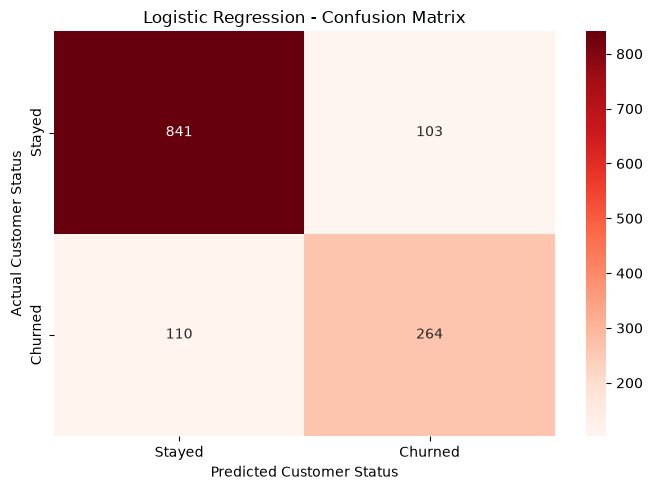

In [12]:
# ==========================================
# CELL 8: CONFUSION MATRIX VISUALIZATION
# ==========================================

# WHAT: Import visualization libraries.
# WHY: 'matplotlib' is the standard Python drawing tool. 'seaborn' is an add-on that makes matplotlib charts look much more modern and colorful with less code.
import matplotlib.pyplot as plt
import seaborn as sns

# WHAT: Grab the raw numbers for the confusion matrix that we calculated in the last cell.
# WHY: We need the actual numbers (True Positives, False Positives, etc.) to draw the chart.
cm = confusion_matrix(y_test, y_pred_lr)

# WHAT: Create a blank canvas for our chart.
# WHY: 'figsize=(7, 5)' sets the width and height in inches so the chart isn't too squished or too massive on your screen.
plt.figure(figsize=(7, 5))

# ------------------------------------------
# Draw the Heatmap
# ------------------------------------------
# WHAT: Draw a color-coded grid (heatmap) using seaborn.
# WHY: Staring at a raw grid of text numbers is hard. A heatmap uses color intensity to instantly show you where the bulk of the predictions landed.
sns.heatmap(
    cm,                           # The 2x2 grid of numbers to plot
    annot=True,                   # WHAT: Turns on annotations. WHY: Actually prints the numbers inside the colored boxes so you can read them.
    fmt="d",                      # WHAT: Format as "decimal" (integers). WHY: Prevents Python from writing numbers in confusing scientific notation (like 1.2e+03).
    cmap="Reds",                 # WHAT: Color map. WHY: Uses shades of blue. Dark blue = big numbers, light blue = small numbers.
    xticklabels=["Stayed", "Churned"], # WHAT/WHY: Replaces the default '0' and '1' on the bottom axis with human-readable words.
    yticklabels=["Stayed", "Churned"]  # WHAT/WHY: Replaces the default '0' and '1' on the side axis with human-readable words.
)

# ------------------------------------------
# Add Labels and Display
# ------------------------------------------
# WHAT: Add a title and label the axes.
# WHY: A chart without labels is useless to anyone else reading your notebook. This clarifies exactly what the viewer is looking at.
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Customer Status")
plt.ylabel("Actual Customer Status")

# WHAT: Automatically adjusts the spacing of the chart.
# WHY: Sometimes the axis labels or titles get cut off by the edges of the window. This forces everything to fit perfectly.
plt.tight_layout()

# WHAT: Finally, render the graphic.
# WHY: In many coding environments, the chart won't actually appear on your screen until you explicitly tell Python to "show" it.
plt.show()

# Cell 9 — Import and train SVM

In [14]:
# ==========================================
# CELL 9: TRAIN SUPPORT VECTOR MACHINE
# ==========================================

# WHAT: Import the Support Vector Classifier (SVC) algorithm.
# WHY: This is a different, often more powerful machine learning algorithm than Logistic Regression. 
# While Logistic Regression tries to draw a straight line between churners and non-churners, SVM can draw complex, curvy boundaries.
from sklearn.svm import SVC

# ------------------------------------------
# Create SVM pipeline
# ------------------------------------------
svm_model = Pipeline(
    steps=[
        # STEP 1: The Cleaning Phase
        # WHAT: We reuse the exact same assembly line (preprocessor) we built in Cell 5.
        # WHY: This ensures our new SVM model gets the exact same clean, scaled data as our Logistic Regression model, making it a fair comparison.
        ("preprocessor", preprocessor),
        
        # STEP 2: The Learning Phase
        # WHAT: We attach the Support Vector Machine to the end of the pipeline with specific settings.
        ("classifier", SVC(
            # WHAT/WHY: 'kernel="rbf"' tells the math to look for circular or curvy patterns instead of just straight lines. RBF (Radial Basis Function) is the best default choice for complex data.
            kernel="rbf",
            
            # WHAT/WHY: 'C=1.0' controls how strict the model is about making mistakes during training. A higher number means it will try very hard to get a perfect score (which might lead to over-memorizing), 1.0 is a balanced default.
            C=1.0,
            
            # WHAT/WHY: SVMs naturally only give hard answers (0 or 1). Setting 'probability=True' forces it to do extra math so it can also tell us its confidence percentage (e.g., "75% sure"). We need this for the ROC-AUC score later.
            probability=True,
            
            # WHAT/WHY: 'random_state=42' locks the randomness. It ensures that if you run this code 10 times, you get the exact same results every time.
            random_state=42
        ))
    ]
)

# ------------------------------------------
# Train SVM
# ------------------------------------------
# WHAT: The `.fit()` command starts the training process.
# WHY: The model looks at the clean training data (X_train) and learns the complex boundaries that separate people who stayed from people who churned (y_train).
svm_model.fit(X_train, y_train)

# Output status messages to confirm success
print("SVM training completed!")

# Print out how much data was used
print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Print out reminders of the specific settings we used
print("\nKernel: RBF")
print("Probability estimation: Enabled")


c:\Users\Asus\Documents\Customer_Churn_ML\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!

Training samples: 5271
Testing samples: 1318

Kernel: RBF
Probability estimation: Enabled


In [ ]:
# ==========================================
# CELL 10: EVALUATE SVM
# ==========================================

# ------------------------------------------
# 1. Generate predictions (Taking the test)
# ------------------------------------------
# WHAT: We hand the SVM model the exact same unseen test questions (X_test) we gave Logistic Regression.
# WHY: `.predict()` forces the SVM to give its final answer: 0 (Stayed) or 1 (Churned).

y_pred_svm = svm_model.predict(X_test)

# WHAT: We ask the SVM for its confidence percentages.
# WHY: `.predict_proba()` calculates the probability. [:, 1] isolates the probability that the customer belongs to class '1' (Churned). 
# Note: We can only do this because we set 'probability=True' in the previous cell!

y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

# ------------------------------------------
# 2. Calculate metrics (Grading the test)
# ------------------------------------------
# WHAT: We use the exact same grading tools from scikit-learn that we imported earlier.
# WHY: By using the identical grading rubric (accuracy, precision, recall, f1, roc-auc), we can do a perfectly fair side-by-side comparison later to see which model is actually smarter.

svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm, zero_division=0)
svm_recall = recall_score(y_test, y_pred_svm, zero_division=0)
svm_f1 = f1_score(y_test, y_pred_svm, zero_division=0)
svm_roc_auc = roc_auc_score(y_test, y_prob_svm)

# ------------------------------------------
# 3. Display results (Printing the Report Card)
# ------------------------------------------
print("========== SVM RESULTS ==========")

# Print out all the calculated grades, rounded to 4 decimal places.
print(f"Accuracy : {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")
print(f"F1 Score : {svm_f1:.4f}")
print(f"ROC-AUC  : {svm_roc_auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

# Print the detailed breakdown showing how well it predicted "Stayed" vs how well it predicted "Churned".
print(    classification_report( y_test,        y_pred_svm,        target_names=["Stayed", "Churned"],        zero_division=0    ) )

print("\n========== CONFUSION MATRIX ==========")

# Print the 2x2 grid showing exactly how many it got right and where it made mistakes.
print(confusion_matrix(y_test, y_pred_svm))

========== SVM RESULTS ==========
Accuracy : 0.8414
Precision: 0.7448
Recall   : 0.6711
F1 Score : 0.7060
ROC-AUC  : 0.9030

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Stayed       0.87      0.91      0.89       944
     Churned       0.74      0.67      0.71       374

    accuracy                           0.84      1318
   macro avg       0.81      0.79      0.80      1318
weighted avg       0.84      0.84      0.84      1318


========== CONFUSION MATRIX ==========
[[858  86]
 [123 251]]


In [ ]:

# ==========================================
# CELL 11: SVM CONFUSION MATRIX
# ==========================================

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted Customer Status")
plt.ylabel("Actual Customer Status")

plt.tight_layout()
plt.show()


In [16]:
# ==========================================
# CELL 12: TRAIN K-NEAREST NEIGHBORS
# ==========================================

# WHAT: Import the K-Nearest Neighbors (KNN) algorithm.
# WHY: This is a completely different approach to machine learning. Instead of drawing lines or curvy boundaries, it makes predictions based on proximity (who is closest to you).
from sklearn.neighbors import KNeighborsClassifier

# ------------------------------------------
# Create KNN pipeline
# ------------------------------------------
knn_model = Pipeline(
    steps=[
        # STEP 1: The Cleaning Phase
        # WHAT: We reuse our trusted assembly line (preprocessor).
        # WHY: This is CRITICAL for KNN! Because KNN calculates the physical distance between data points, unscaled numbers (like a $100,000 salary) would completely overpower small numbers (like 2 children). The preprocessor's StandardScaler prevents this.
        ("preprocessor", preprocessor),
        
        # STEP 2: The Learning Phase
        # WHAT: Attach the KNN model with specific settings.
        ("classifier", KNeighborsClassifier(
            # WHAT/WHY: 'n_neighbors=5' is the "K" in KNN. When predicting a new customer, the model will look at the 5 most similar customers in the historical data to make its decision.
            n_neighbors=5,
            
            # WHAT/WHY: 'weights="uniform"' means all 5 neighbors get an equal vote. (The alternative is "distance", where closer neighbors get a louder voice).
            weights="uniform",
            
            # WHAT/WHY: 'metric="minkowski"' and 'p=2' is the mathematical way of telling the model to measure distance using a standard straight line (Euclidean distance), just like you would with a ruler.
            metric="minkowski",
            p=2
        ))
    ]
)

# ------------------------------------------
# Train KNN
# ------------------------------------------
# WHAT: The `.fit()` command prepares the model.
# WHY: Unlike Logistic Regression or SVM which learn an actual mathematical equation, KNN is "lazy." The `.fit()` step essentially just memorizes the entire X_train dataset so it can use it as a reference map later.
knn_model.fit(X_train, y_train)

# Output status messages to confirm success
print("KNN training completed!")

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nNumber of neighbors: 5")
print("Distance metric: Euclidean")

KNN training completed!

Training samples: 5271
Testing samples: 1318

Number of neighbors: 5
Distance metric: Euclidean


In [18]:
# ==========================================
# CELL 12: TRAIN K-NEAREST NEIGHBORS
# ==========================================

# WHAT: Import the K-Nearest Neighbors (KNN) algorithm.
# WHY: This is a completely different approach to machine learning. Instead of drawing lines or curvy boundaries, it makes predictions based on proximity (who is closest to you).
from sklearn.neighbors import KNeighborsClassifier

# ------------------------------------------
# Create KNN pipeline
# ------------------------------------------
knn_model = Pipeline(
    steps=[
        # STEP 1: The Cleaning Phase
        # WHAT: We reuse our trusted assembly line (preprocessor).
        # WHY: This is CRITICAL for KNN! Because KNN calculates the physical distance between data points, unscaled numbers (like a $100,000 salary) would completely overpower small numbers (like 2 children). The preprocessor's StandardScaler prevents this.
        ("preprocessor", preprocessor),
        
        # STEP 2: The Learning Phase
        # WHAT: Attach the KNN model with specific settings.
        ("classifier", KNeighborsClassifier(
            # WHAT/WHY: 'n_neighbors=5' is the "K" in KNN. When predicting a new customer, the model will look at the 5 most similar customers in the historical data to make its decision.
            n_neighbors=5,
            
            # WHAT/WHY: 'weights="uniform"' means all 5 neighbors get an equal vote. (The alternative is "distance", where closer neighbors get a louder voice).
            weights="uniform",
            
            # WHAT/WHY: 'metric="minkowski"' and 'p=2' is the mathematical way of telling the model to measure distance using a standard straight line (Euclidean distance), just like you would with a ruler.
            metric="minkowski",
            p=2
        ))
    ]
)

# ------------------------------------------
# Train KNN
# ------------------------------------------
# WHAT: The `.fit()` command prepares the model.
# WHY: Unlike Logistic Regression or SVM which learn an actual mathematical equation, KNN is "lazy." The `.fit()` step essentially just memorizes the entire X_train dataset so it can use it as a reference map later.
knn_model.fit(X_train, y_train)

# Output status messages to confirm success
print("KNN training completed!")

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nNumber of neighbors: 5")
print("Distance metric: Euclidean")

KNN training completed!

Training samples: 5271
Testing samples: 1318

Number of neighbors: 5
Distance metric: Euclidean


In [19]:

# ==========================================
# CELL 13: EVALUATE KNN
# ==========================================

# Generate predictions
y_pred_knn = knn_model.predict(X_test)

# Get churn probabilities
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

# Calculate metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test, y_pred_knn, zero_division=0
)

knn_recall = recall_score(
    y_test, y_pred_knn, zero_division=0
)

knn_f1 = f1_score(
    y_test, y_pred_knn, zero_division=0
)

knn_roc_auc = roc_auc_score(y_test, y_prob_knn)

# Display results
print("========== KNN RESULTS ==========")

print(f"Accuracy : {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall   : {knn_recall:.4f}")
print(f"F1 Score : {knn_f1:.4f}")
print(f"ROC-AUC  : {knn_roc_auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)

print("\n========== CONFUSION MATRIX ==========")

print(confusion_matrix(y_test, y_pred_knn))


========== KNN RESULTS ==========
Accuracy : 0.8187
Precision: 0.6901
Recall   : 0.6551
F1 Score : 0.6722
ROC-AUC  : 0.8561

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Stayed       0.87      0.88      0.87       944
     Churned       0.69      0.66      0.67       374

    accuracy                           0.82      1318
   macro avg       0.78      0.77      0.77      1318
weighted avg       0.82      0.82      0.82      1318


========== CONFUSION MATRIX ==========
[[834 110]
 [129 245]]


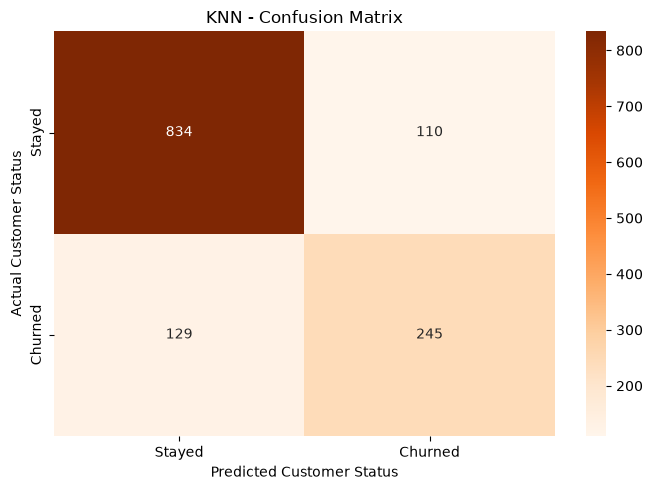

In [20]:

# ==========================================
# CELL 14: KNN CONFUSION MATRIX
# ==========================================

cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Customer Status")
plt.ylabel("Actual Customer Status")

plt.tight_layout()
plt.show()


In [21]:

# ==========================================
# CELL 15: COMPARE ALL THREE ML MODELS
# ==========================================

import pandas as pd

comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "KNN"
    ],
    "Accuracy": [
        accuracy,
        svm_accuracy,
        knn_accuracy
    ],
    "Precision": [
        precision,
        svm_precision,
        knn_precision
    ],
    "Recall": [
        recall,
        svm_recall,
        knn_recall
    ],
    "F1 Score": [
        f1,
        svm_f1,
        knn_f1
    ],
    "ROC-AUC": [
        roc_auc,
        svm_roc_auc,
        knn_roc_auc
    ]
})

# Display comparison
comparison_df = comparison_df.round(4)

display(comparison_df)

print("\n========== BEST MODEL BY METRIC ==========")

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]:
    best_index = comparison_df[metric].idxmax()

    print(
        f"{metric}: "
        f"{comparison_df.loc[best_index, 'Model']} "
        f"({comparison_df.loc[best_index, metric]:.4f})"
    )



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8384,0.7193,0.7059,0.7126,0.9059
1,SVM,0.8414,0.7448,0.6711,0.7060,0.9030
2,KNN,0.8187,0.6901,0.6551,0.6722,0.8561



========== BEST MODEL BY METRIC ==========
Accuracy: SVM (0.8414)
Precision: SVM (0.7448)
Recall: Logistic Regression (0.7059)
F1 Score: Logistic Regression (0.7126)
ROC-AUC: Logistic Regression (0.9059)


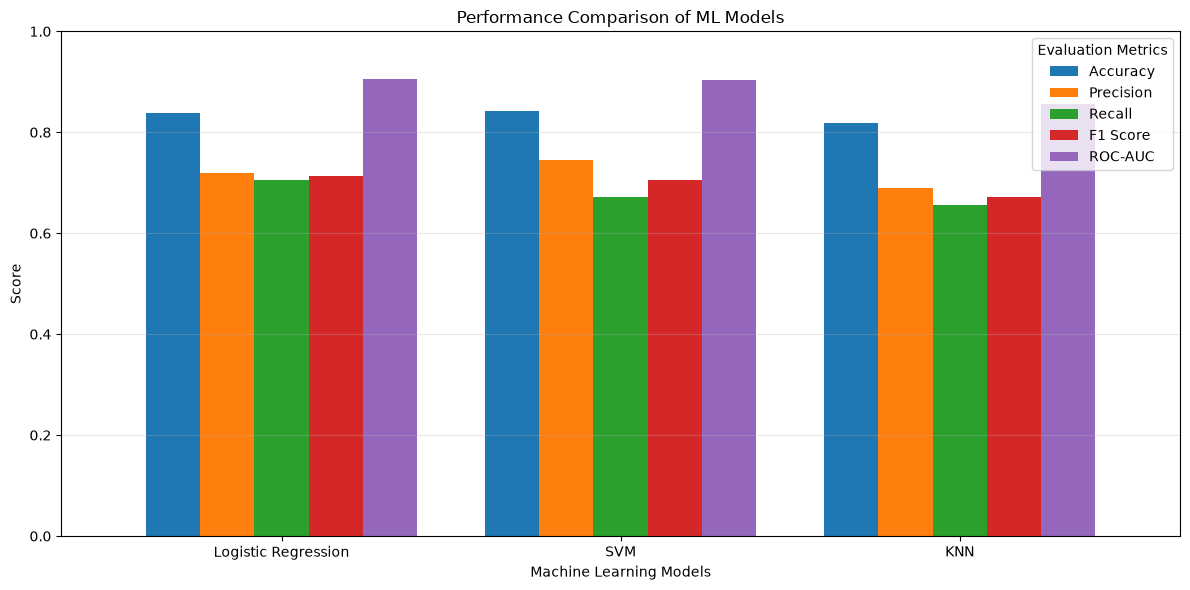

In [22]:

# ==========================================
# CELL 16: MODEL PERFORMANCE VISUALIZATION
# ==========================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_plot = comparison_df.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [23]:

# ==========================================
# CELL 17: SAVE ALL TRAINED ML MODELS
# ==========================================

import joblib
from pathlib import Path

# Create models directory if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save all three complete pipelines
joblib.dump(
    logistic_model,
    models_dir / "logistic_regression_pipeline.pkl"
)

joblib.dump(
    svm_model,
    models_dir / "svm_pipeline.pkl"
)

joblib.dump(
    knn_model,
    models_dir / "knn_pipeline.pkl"
)

print("All models saved successfully!")

print("\nSaved model files:")

for file in models_dir.glob("*.pkl"):
    print(f"{file.name} - {file.stat().st_size / 1024:.2f} KB")


All models saved successfully!

Saved model files:
knn_pipeline.pkl - 1406.80 KB
logistic_regression_pipeline.pkl - 6.99 KB
svm_pipeline.pkl - 531.18 KB


In [24]:

# ==========================================
# CELL 18: VERIFY SAVED MODELS
# ==========================================

saved_models = {
    "Logistic Regression": models_dir / "logistic_regression_pipeline.pkl",
    "SVM": models_dir / "svm_pipeline.pkl",
    "KNN": models_dir / "knn_pipeline.pkl"
}

for model_name, model_path in saved_models.items():

    loaded_model = joblib.load(model_path)

    print(f"{model_name}: Loaded successfully")

print("\nSUCCESS: All three models are ready for the web application.")


Logistic Regression: Loaded successfully
SVM: Loaded successfully
KNN: Loaded successfully

SUCCESS: All three models are ready for the web application.


In [25]:

# ==========================================
# CELL 19: EXPORT WEB APP CONFIGURATION
# ==========================================

import json

# Store the exact categories learned from the modeling dataset
app_config = {
    "categorical_options": {
        column: sorted(X_train[column].dropna().unique().tolist())
        for column in categorical_features
    },
    "numerical_defaults": {
        column: float(X_train[column].median())
        for column in numerical_features
    },
    "numerical_min": {
        column: float(X_train[column].min())
        for column in numerical_features
    },
    "numerical_max": {
        column: float(X_train[column].max())
        for column in numerical_features
    }
}

# Save configuration
config_path = models_dir / "app_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(app_config, file, indent=4)

print("Web application configuration saved!")
print("\nConfiguration file:", config_path)

print("\nCategorical options:")
for column, values in app_config["categorical_options"].items():
    print(f"{column}: {values}")

print("\nNumerical defaults:")
for column, value in app_config["numerical_defaults"].items():
    print(f"{column}: {value}")


Web application configuration saved!

Configuration file: ..\models\app_config.json

Categorical options:
Married: ['No', 'Yes']
Internet Service: ['No', 'Yes']
Internet Type: ['Cable', 'DSL', 'Fiber Optic', 'No Internet Service']
Online Security: ['No', 'No Internet Service', 'Yes']
Online Backup: ['No', 'No Internet Service', 'Yes']
Device Protection Plan: ['No', 'No Internet Service', 'Yes']
Premium Tech Support: ['No', 'No Internet Service', 'Yes']
Contract: ['Month-to-Month', 'One Year', 'Two Year']
Paperless Billing: ['No', 'Yes']
Payment Method: ['Bank Withdrawal', 'Credit Card', 'Mailed Check']

Numerical defaults:
Age: 46.0
Number of Dependents: 0.0
Number of Referrals: 0.0
Tenure in Months: 33.0
Monthly Charge: 71.45


In [27]:

# ==========================================
# CELL 20: SAVE MODEL COMPARISON RESULTS
# ==========================================

from pathlib import Path
import pandas as pd
from sklearn.metrics import confusion_matrix

# Create reports directory
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. SAVE MODEL COMPARISON TABLE
# --------------------------------------------------

comparison_df.to_csv(
    reports_dir / "model_comparison.csv",
    index=False
)

# --------------------------------------------------
# 2. GENERATE CONFUSION MATRICES
# --------------------------------------------------

confusion_matrices = {
    "Logistic Regression": confusion_matrix(
        y_test, y_pred_lr
    ),

    "SVM": confusion_matrix(
        y_test, y_pred_svm
    ),

    "KNN": confusion_matrix(
        y_test, y_pred_knn
    )
}

# --------------------------------------------------
# 3. SAVE EACH CONFUSION MATRIX
# --------------------------------------------------

for model_name, matrix in confusion_matrices.items():

    safe_name = model_name.lower().replace(" ", "_")

    matrix_df = pd.DataFrame(
        matrix,
        index=["Actual Stayed", "Actual Churned"],
        columns=[
            "Predicted Stayed",
            "Predicted Churned"
        ]
    )

    matrix_df.to_csv(
        reports_dir / f"{safe_name}_confusion_matrix.csv"
    )

    print(f"\n{model_name}")
    display(matrix_df)

# --------------------------------------------------
# 4. DISPLAY SAVED FILES
# --------------------------------------------------

print("\n===================================")
print("MODEL REPORTS SAVED SUCCESSFULLY!")
print("===================================")

for file in sorted(reports_dir.glob("*.csv")):

    print(file.name)



Logistic Regression


,Predicted Stayed,Predicted Churned
Actual Stayed,841,103
Actual Churned,110,264



SVM


,Predicted Stayed,Predicted Churned
Actual Stayed,858,86
Actual Churned,123,251



KNN


,Predicted Stayed,Predicted Churned
Actual Stayed,834,110
Actual Churned,129,245



MODEL REPORTS SAVED SUCCESSFULLY!
knn_confusion_matrix.csv
logistic_regression_confusion_matrix.csv
model_comparison.csv
svm_confusion_matrix.csv
